<a href="https://colab.research.google.com/github/jungyouha/cds230/blob/main/lab7/svm_optdigits.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SVM on the Optical Recognition of Handwritten Digits Dataset

**Dataset:** UCI Machine Learning Repository — *Optical Recognition of Handwritten Digits* (1998).
43 people wrote digits on a form. Each digit was scanned, shrunk to an **8×8 grid**, and every cell
stores how much ink it has (0 = blank … 16 = fully dark). So each digit = **64 numbers**, plus the true digit (0–9).
- `optdigits.tra`: 3,823 training digits (written by 30 people)
- `optdigits.tes`: 1,797 test digits (written by 13 *different* people)

**Goal:** Train a Support Vector Machine to read handwritten digits, and test it on handwriting it has never seen.

**Before running:** upload `optdigits.tra` and `optdigits.tes` with the 📁 folder icon on the left.
(If you skip the upload, the next cell downloads them from UCI automatically.)

## Step 0 — Load the data

In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
import time

base_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/optdigits/'
cols = [f'pixel_{i}' for i in range(64)] + ['digit']

def load(name):
    path = name if os.path.exists(name) else base_url + name
    return pd.read_csv(path, header=None, names=cols)

train = load('optdigits.tra')
test  = load('optdigits.tes')

X_train, y_train = train[cols[:-1]].values, train['digit'].values
X_test,  y_test  = test[cols[:-1]].values,  test['digit'].values

print('Training set:', X_train.shape)   # expect (3823, 64)
print('Test set    :', X_test.shape)    # expect (1797, 64)
print()
print('Digits per class (training):')
print(pd.Series(y_train).value_counts().sort_index().to_string())

Training set: (3823, 64)
Test set    : (1797, 64)

Digits per class (training):
0    376
1    389
2    380
3    389
4    387
5    376
6    377
7    387
8    380
9    382


## Look at the data — what does the computer actually see?

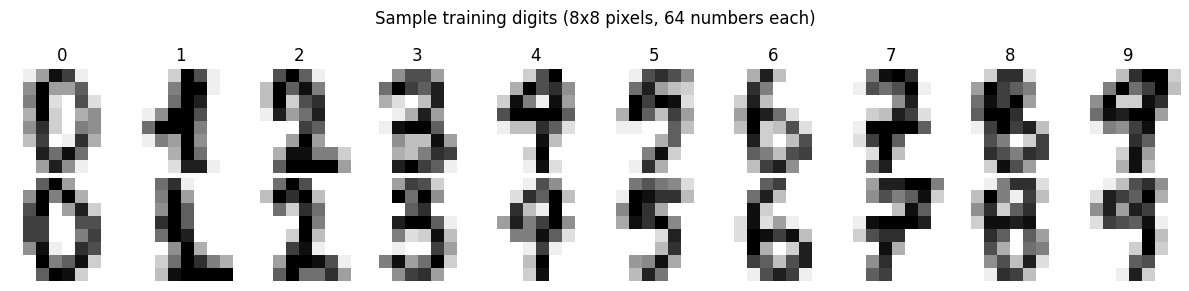

In [22]:
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for d in range(10):
    for row in range(2):
        idx = np.where(y_train == d)[0][row]
        axes[row, d].imshow(X_train[idx].reshape(8, 8), cmap='gray_r')
        axes[row, d].axis('off')
        if row == 0:
            axes[row, d].set_title(str(d))
plt.suptitle('Sample training digits (8x8 pixels, 64 numbers each)')
plt.tight_layout()
plt.savefig('svm_sample_digits.png', dpi=150)
plt.show()

## Step 1 — Standardize
SVM measures distances to the separating hyperplane, so features should be on the same scale. The scaler is fit on the **training set only** and then applied to the test set (no peeking at test data).

In [23]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)
print('Train mean {:.3f}, std {:.3f}'.format(X_train_s.mean(), X_train_s.std()))

Train mean -0.000, std 0.984


## Step 2 — Linear SVM vs. RBF (kernel) SVM
- **Linear kernel:** separates classes with straight hyperplanes.
- **RBF kernel:** uses the *kernel trick* — like the slide example Z = X² + Y², it looks at the data in a
  higher dimension where curved boundaries become possible.

In [24]:
results = {}
for kernel in ['linear', 'rbf']:
    start = time.time()
    model = SVC(kernel=kernel, C=1.0).fit(X_train_s, y_train)
    acc = accuracy_score(y_test, model.predict(X_test_s))
    results[kernel] = model
    print(f'{kernel:6s} kernel: test accuracy = {acc:.2%}   '
          f'support vectors = {model.n_support_.sum():4d}   time = {time.time() - start:.1f}s')

linear kernel: test accuracy = 95.94%   support vectors =  637   time = 0.2s
rbf    kernel: test accuracy = 96.77%   support vectors = 1309   time = 0.5s


## Step 3 — Tune C and gamma (5-fold cross-validation on the training set)
- **C** controls the margin: small C = wide, forgiving margin (risk of *underfitting*);
  large C = narrow, strict margin (risk of *overfitting*).
- **gamma** (RBF only) controls how far each training point's influence reaches.

In [25]:
param_grid = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.001, 0.01, 0.1]}
grid = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, n_jobs=-1)
grid.fit(X_train_s, y_train)

print('Best parameters      :', grid.best_params_)
print('Best CV accuracy     : {:.2%}'.format(grid.best_score_))

scores = pd.DataFrame(grid.cv_results_)[['param_C', 'param_gamma', 'mean_test_score']]
print()
print(scores.pivot(index='param_C', columns='param_gamma', values='mean_test_score').round(4))

Best parameters      : {'C': 10, 'gamma': 0.01}
Best CV accuracy     : 98.64%

param_gamma   0.001    0.01     0.1   scale
param_C                                    
0.1          0.9071  0.9519  0.7560  0.9534
1.0          0.9639  0.9822  0.9451  0.9820
10.0         0.9793  0.9864  0.9474  0.9848
100.0        0.9817  0.9859  0.9474  0.9848


## Step 4 — Final evaluation on the unseen test set

In [26]:
best = grid.best_estimator_
y_pred = best.predict(X_test_s)
test_acc = accuracy_score(y_test, y_pred)

print('Test accuracy: {:.2%}  ({} of {} digits correct)'.format(
      test_acc, (y_pred == y_test).sum(), len(y_test)))
print()
print(classification_report(y_test, y_pred, digits=3))

Test accuracy: 97.05%  (1744 of 1797 digits correct)

              precision    recall  f1-score   support

           0      0.994     1.000     0.997       178
           1      0.938     0.989     0.963       182
           2      0.977     0.960     0.969       177
           3      0.989     0.940     0.964       183
           4      0.968     0.989     0.978       181
           5      0.973     0.995     0.984       182
           6      0.989     0.994     0.992       181
           7      0.983     0.950     0.966       179
           8      0.970     0.920     0.944       174
           9      0.930     0.967     0.948       180

    accuracy                          0.971      1797
   macro avg      0.971     0.970     0.970      1797
weighted avg      0.971     0.971     0.970      1797



## Confusion matrix — which digits get mixed up?

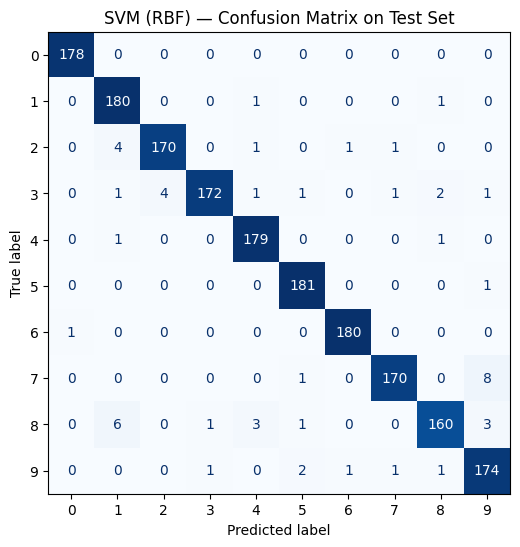

Most common mistakes (true -> predicted):
  7 -> 9: 8 times
  8 -> 1: 6 times
  3 -> 2: 4 times
  2 -> 1: 4 times
  8 -> 9: 3 times


In [27]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('SVM (RBF) — Confusion Matrix on Test Set')
plt.savefig('svm_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

cm = confusion_matrix(y_test, y_pred)
np.fill_diagonal(cm, 0)
pairs = [(cm[i, j], i, j) for i in range(10) for j in range(10) if cm[i, j] > 0]
print('Most common mistakes (true -> predicted):')
for count, t, p in sorted(pairs, reverse=True)[:5]:
    print(f'  {t} -> {p}: {count} times')

## Look at the mistakes

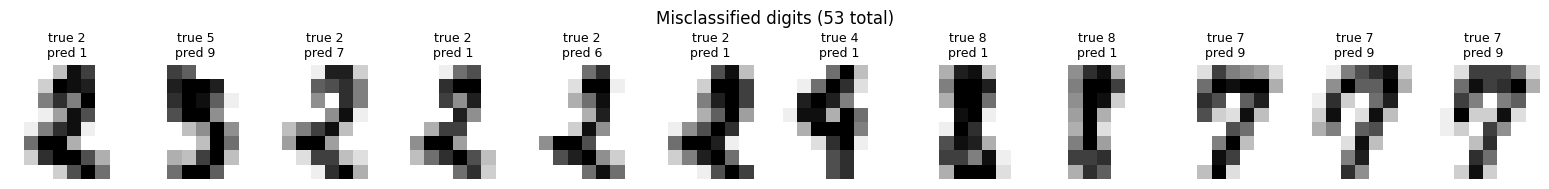

In [28]:
wrong = np.where(y_pred != y_test)[0]
n_show = min(len(wrong), 12)
fig, axes = plt.subplots(1, n_show, figsize=(1.3 * n_show, 2))
axes = np.atleast_1d(axes)
for ax, idx in zip(axes, wrong[:n_show]):
    ax.imshow(X_test[idx].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'true {y_test[idx]}\npred {y_pred[idx]}', fontsize=9)
    ax.axis('off')
plt.suptitle(f'Misclassified digits ({len(wrong)} total)')
plt.tight_layout()
plt.savefig('svm_mistakes.png', dpi=150)
plt.show()

## Multi-class strategies: One-vs-One vs One-vs-All
SVM is originally a **binary** classifier. For 10 digits:
- **One-vs-One (OvO):** one SVM per pair of digits → 10×9/2 = **45 classifiers**, prediction by voting.
- **One-vs-All (OvA / OvR):** one SVM per digit ("this digit vs. everything else") → **10 classifiers**,
  prediction by highest confidence score.

In [29]:
params = dict(kernel='rbf', **grid.best_params_)
for name, wrapper in [('One-vs-One', OneVsOneClassifier), ('One-vs-All', OneVsRestClassifier)]:
    start = time.time()
    m = wrapper(SVC(**params)).fit(X_train_s, y_train)
    acc = accuracy_score(y_test, m.predict(X_test_s))
    print(f'{name}: {len(m.estimators_):2d} classifiers, test accuracy = {acc:.2%}, '
          f'time = {time.time() - start:.1f}s')

One-vs-One: 45 classifiers, test accuracy = 97.05%, time = 1.5s
One-vs-All: 10 classifiers, test accuracy = 97.27%, time = 2.3s


## Automatic plain-language summary (uses your actual numbers)

In [30]:
top_mistake = sorted(pairs, reverse=True)[0] if pairs else (0, '-', '-')
print(f'''
- We trained an SVM on {len(y_train):,} handwritten digits from 30 people and tested it on
  {len(y_test):,} digits written by 13 other people.
- Each digit is just an 8x8 grid of ink levels (64 numbers).
- A straight-line (linear) SVM got {accuracy_score(y_test, results["linear"].predict(X_test_s)):.1%};
  the curved-boundary (RBF kernel) SVM, after tuning, got {test_acc:.1%}.
- It read {(y_pred == y_test).sum():,} of {len(y_test):,} digits correctly and missed {len(wrong)}.
- The most common mix-up was {top_mistake[1]} read as {top_mistake[2]} ({top_mistake[0]} times).
''')


- We trained an SVM on 3,823 handwritten digits from 30 people and tested it on
  1,797 digits written by 13 other people.
- Each digit is just an 8x8 grid of ink levels (64 numbers).
- A straight-line (linear) SVM got 95.9%;
  the curved-boundary (RBF kernel) SVM, after tuning, got 97.1%.
- It read 1,744 of 1,797 digits correctly and missed 53.
- The most common mix-up was 7 read as 9 (8 times).



I used an SVM model to recognize handwritten digits from 0 to 9. The model was trained on 3,823 images and tested on 1,797 images. I compared linear SVM and RBF SVM, and the RBF model performed better, with 97.1% accuracy. It correctly identified 1,744 digits and made 53 mistakes. The most common mistake was predicting 7 as 9. I also compared One-vs-One and One-vs-All, which achieved similar accuracy. This shows that SVM can recognize handwritten digits accurately, although some similar-looking numbers are difficult to distinguish.